# CS781 Phase 6 — Experiment 3
## Phase-1 Model 2 (Decoder Only) + QLoRA (NF4)

**Goal:** Fine-tune the user's Phase-1 Model 2 checkpoint for abstractive Indian legal summarization using 4-bit NF4 quantization and trainable LoRA adapters. The original Phase-1 tokenizer and checkpoint are mandatory; no external pretrained model is used.

**QLoRA design:** Quantize every transformer `nn.Linear` projection to bitsandbytes NF4 (double quantization), keep the tied token embedding/output matrix frozen in FP16, and train rank-16 LoRA adapters on fused attention QKV, attention output, and both feed-forward projections.

**Important:** Model 2 is a custom PyTorch decoder-only model, not a Hugging Face `PreTrainedModel`. This notebook therefore implements QLoRA directly around its custom linear layers rather than calling `prepare_model_for_kbit_training`.


**Improvements in this version:** finer checkpoint selection (every 250 steps), a wider decoding grid, with selection by primary BERTScore F1 and ROUGE metrics retained as secondary diagnostics, memory cleanup before generation, corrected metadata labels, a training-curve plot, and prediction-quality sanity checks. The core model, QLoRA implementation and data pipeline are unchanged.

**Validation policy:** duplicate-grouped split; decoding tuning uses 32 validation rows disjoint from the final 100 scored rows.

**Checkpoint discovery:** searches for a unique `dec_full_best*.pt` file (including Kaggle duplicate suffixes); set `CHECKPOINT_PATH` explicitly if more than one exists.

In [16]:
# 0. Environment and imports
import os, sys, json, math, random, time, gc, hashlib, re, subprocess, importlib
from pathlib import Path
from collections import defaultdict
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


SEED = 2026

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_CUDA = DEVICE.type == "cuda"
if USE_CUDA:
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    # bf16 only where it is natively supported (Ampere+); T4/P100 use fp16 + GradScaler.
    AMP_DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
else:
    AMP_DTYPE = torch.float16   # unused: autocast is disabled on CPU
USE_GRAD_SCALER = USE_CUDA and AMP_DTYPE == torch.float16
torch.set_float32_matmul_precision("high")

def amp_ctx():
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_CUDA)

def ensure_package(import_name, pip_name=None):
    # Import a package, pip-installing it first if it is missing.
    try:
        return importlib.import_module(import_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or import_name])
        importlib.invalidate_caches()
        return importlib.import_module(import_name)

print("torch", torch.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if USE_CUDA else "CPU",
      "| AMP:", str(AMP_DTYPE).replace("torch.", "") if USE_CUDA else "off")

# QLoRA dependency (T4-compatible 4-bit NF4 kernels)
ensure_package("bitsandbytes", "bitsandbytes")
import bitsandbytes as bnb
print("bitsandbytes:", bnb.__version__)


torch 2.11.0+cu128 | device: cuda | Tesla T4 | AMP: float16
bitsandbytes: 0.50.2


In [17]:
# 1. CONFIGURATION — Model 2 + QLoRA
# Leave paths as None for safe auto-discovery, or set explicit Kaggle paths.

CHECKPOINT_PATH = None
TOKENIZER_PATH  = None
TRAIN_JSON_PATH = None
TEST_JSON_PATH  = None

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
HF_DATASET_SUBDIR = "Phase_6_Summ"
HF_TOKEN_SECRET_NAME = "HF_TOKEN"
CHECKPOINT_FILENAME = "dec_full_best.pt"

ON_KAGGLE = Path("/kaggle/input").exists()
OUTPUT_DIR = Path("/kaggle/working/phase6_exp3_model2_qlora") if ON_KAGGLE else Path("./phase6_exp3_model2_qlora")
SEARCH_ROOTS = [Path("/kaggle/input"), Path("/kaggle/working"), Path.cwd()]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Keep identical to Experiment 1 for a fair comparison.
SEED = 2026   # matches the Experiment-1 duplicate-grouped validation split
VAL_FRACTION = 0.05
MAX_SOURCE_TOKENS = 1500
MAX_TARGET_TOKENS = 800
MAX_SEQ_LEN = 2048  # Model-2 Phase-1 max_positions is 2048

# Score-focused budget, bounded to the requested 3–4 hour total runtime.
MICRO_BATCH_SIZE = 1
GRAD_ACCUM_STEPS = 8
NUM_EPOCHS = 3
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.05
MAX_GRAD_NORM = 1.0
LOG_EVERY = 50
EVAL_EVERY = 250   # finer-grained best-checkpoint selection
SAVE_EVERY = 250
EVAL_MAX_EXAMPLES = 100

RESUME = False
RESUME_TEST_PREDICTIONS = True

# QLoRA: NF4-quantized frozen W0 + (alpha / rank) * B(A(dropout(x)))
LORA_RANK = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05
LORA_TARGETS = ("qkv", "out_proj", "ff.0", "ff.2")
# QLoRA: NF4 4-bit base weights + double quantization. Adapters remain FP16.
BNB_4BIT_QUANT_TYPE = "nf4"
BNB_4BIT_USE_DOUBLE_QUANT = True
QLORA_COMPUTE_DTYPE = torch.float16 if USE_CUDA else torch.float32

# Decoding and validation. Full 100-document validation is retained for a stable comparison.
GEN_MAX_NEW_TOKENS = 800
NO_REPEAT_NGRAM_SIZE = 0     # only used by the old per-document generate_summary; the tuned grid below decides
VAL_SCORE_EXAMPLES = 100
BERTSCORE_BATCH_SIZE = 8
RUN_TEST_INFERENCE = True

# ---- source selection (replaces plain head+tail) ----
SELECTOR_MODE = "auto"        # "auto" | "lead" | "headtail" | "tfidf" | "learned"
SELECTOR_FIT_DOCS = 2500      # training docs used to fit the sentence scorer
SELECTOR_EVAL_DOCS = 150      # validation docs used to compare selectors by coverage

# ---- batched generation + decoding-grid tuning ----
GEN_BATCH_SIZE = 8            # lower to 4 if CUDA runs out of memory (it also halves a batch automatically)
N_TUNE_DOCS = 32              # validation docs val_rows[100:132] (disjoint from the 100 scored docs)
# min_frac: EOS blocked until min_frac*GEN_MAX_NEW_TOKENS tokens; ngram: no-repeat n-gram (tokens; 0=off); rep: repetition penalty
GEN_GRID = [
    dict(name="greedy",           min_frac=0.00, ngram=0,  rep=1.00),
    dict(name="greedy+min",       min_frac=0.45, ngram=0,  rep=1.00),
    dict(name="ng12+min",         min_frac=0.45, ngram=12, rep=1.00),
    dict(name="ng20+min",         min_frac=0.45, ngram=20, rep=1.00),
    dict(name="ng20+rep1.05+min", min_frac=0.45, ngram=20, rep=1.05),
    dict(name="ng12+min60",       min_frac=0.60, ngram=12, rep=1.00),
    dict(name="ng8+rep1.05+min60",min_frac=0.60, ngram=8,  rep=1.05),
]
# BERTScore F1 is the primary leaderboard metric; ROUGE is reported as secondary diagnostics.
def composite_score(m):
    return (m["rouge1_f1"] + m["rougeL_f1"] + m["bertscore_f1"]) / 3.0
set_seed(SEED)

assert MICRO_BATCH_SIZE >= 1 and GRAD_ACCUM_STEPS >= 1 and NUM_EPOCHS >= 1
assert 0.0 < VAL_FRACTION < 0.5 and 0.0 <= WARMUP_RATIO < 1.0
assert LORA_RANK > 0 and LORA_ALPHA > 0 and 0 <= NO_REPEAT_NGRAM_SIZE
print("Output:", OUTPUT_DIR.resolve())
print(f"LoRA: rank={LORA_RANK}, alpha={LORA_ALPHA}, scaling={LORA_ALPHA/LORA_RANK:.3f}, dropout={LORA_DROPOUT}")
print("Targets:", LORA_TARGETS)
print(f"Training budget: {NUM_EPOCHS} epochs; full validation generation: {VAL_SCORE_EXAMPLES} docs")



Output: /kaggle/working/phase6_exp3_model2_qlora
LoRA: rank=16, alpha=32, scaling=2.000, dropout=0.05
Targets: ('qkv', 'out_proj', 'ff.0', 'ff.2')
Training budget: 3 epochs; full validation generation: 100 docs


In [18]:
# 2. Locate model files and fetch Phase 6 data from Hugging Face
def find_unique(filename, explicit=None):
    if explicit:
        p = Path(explicit)
        if not p.is_file():
            raise FileNotFoundError(p)
        return p
    hits = {}
    for root in SEARCH_ROOTS:
        if root.exists():
            for x in root.rglob(filename):
                if x.is_file():
                    hits[x.resolve()] = x
    hits = list(hits.values())
    if not hits:
        raise FileNotFoundError(
            f"Could not find {filename}. Set its explicit path in the configuration cell."
        )
    if len(hits) > 1:
        print("Multiple candidates for", filename)
        for x in hits[:20]:
            print("  ", x)
        raise RuntimeError(f"Set an explicit path for {filename} in the configuration cell.")
    return hits[0]

def get_hf_token():
    # Kaggle Secrets is optional for public datasets, but required for gated/private access.
    if os.environ.get("HF_TOKEN"):
        return os.environ["HF_TOKEN"]
    if ON_KAGGLE:
        try:
            from kaggle_secrets import UserSecretsClient
            return UserSecretsClient().get_secret(HF_TOKEN_SECRET_NAME)
        except Exception as exc:
            print(
                f"Could not read Kaggle secret '{HF_TOKEN_SECRET_NAME}'. "
                "Continuing without a token; this works only if the dataset is public."
            )
    return None

def download_phase6_jsons():
    try:
        from huggingface_hub import HfApi, hf_hub_download
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"])
        from huggingface_hub import HfApi, hf_hub_download

    token = get_hf_token()
    api = HfApi(token=token)
    repo_files = api.list_repo_files(
        repo_id=HF_DATASET_REPO, repo_type="dataset", token=token
    )
    print(f"Found {len(repo_files)} files in dataset repository {HF_DATASET_REPO}")

    def choose_file(kind):
        # Accommodate the repository's Train/Test folders and minor filename variations.
        candidates = [
            name for name in repo_files
            if name.lower().endswith(".json")
            and HF_DATASET_SUBDIR.lower() in name.lower()
            and kind.lower() in [part.lower() for part in name.replace("\\", "/").split("/")]
        ]
        # Prefer exact conventional names if multiple JSONs exist.
        preferred = [name for name in candidates
                     if Path(name).name.lower() == f"{kind.lower()}.json"]
        candidates = preferred or candidates
        if len(candidates) != 1:
            print(f"Candidate {kind} JSON files:")
            for name in candidates:
                print("  ", name)
            raise FileNotFoundError(
                f"Expected exactly one {kind} JSON under {HF_DATASET_SUBDIR}; "
                "inspect the listed candidates and set TRAIN_JSON_PATH/TEST_JSON_PATH explicitly."
            )
        return candidates[0]

    train_file = choose_file("Train")
    test_file = choose_file("Test")
    print("HF train file:", train_file)
    print("HF test file :", test_file)

    train_local = hf_hub_download(
        repo_id=HF_DATASET_REPO, filename=train_file, repo_type="dataset", token=token
    )
    test_local = hf_hub_download(
        repo_id=HF_DATASET_REPO, filename=test_file, repo_type="dataset", token=token
    )
    return Path(train_local), Path(test_local)

# The Phase-1 checkpoint and tokenizer are separate from this HF dataset.
# Kaggle may append duplicate suffixes such as "dec_full_best (8).pt".
if CHECKPOINT_PATH is not None:
    CHECKPOINT_PATH = find_unique(Path(CHECKPOINT_PATH).name, CHECKPOINT_PATH)
else:
    checkpoint_hits = {}
    for root in SEARCH_ROOTS:
        if root.exists():
            for x in root.rglob("dec_full_best*.pt"):
                if x.is_file():
                    checkpoint_hits[x.resolve()] = x
    if len(checkpoint_hits) != 1:
        print("Model-2 checkpoint candidates:")
        for x in list(checkpoint_hits.values())[:30]: print("  ", x)
        raise RuntimeError("Expected exactly one dec_full_best*.pt; set CHECKPOINT_PATH explicitly.")
    CHECKPOINT_PATH = list(checkpoint_hits.values())[0]
TOKENIZER_PATH = find_unique("tokenizer (1).json", TOKENIZER_PATH)

if TRAIN_JSON_PATH is None or TEST_JSON_PATH is None:
    hf_train_path, hf_test_path = download_phase6_jsons()
    TRAIN_JSON_PATH = Path(TRAIN_JSON_PATH) if TRAIN_JSON_PATH else hf_train_path
    TEST_JSON_PATH = Path(TEST_JSON_PATH) if TEST_JSON_PATH else hf_test_path
else:
    TRAIN_JSON_PATH = find_unique("train.json", TRAIN_JSON_PATH)
    TEST_JSON_PATH = find_unique("test.json", TEST_JSON_PATH)

for label, pth in [("Checkpoint", CHECKPOINT_PATH), ("Tokenizer ", TOKENIZER_PATH),
                   ("Train     ", TRAIN_JSON_PATH), ("Test      ", TEST_JSON_PATH)]:
    if not Path(pth).is_file():
        raise FileNotFoundError(f"{label.strip()} file does not exist: {pth}")
    print(f"{label}: {pth}")


Found 34 files in dataset repository Exploration-Lab/CS-781-Capstone
HF train file: Phase_6_Summ/Train/train.json
HF test file : Phase_6_Summ/Test/test.json
Checkpoint: /kaggle/input/datasets/aaryant23/phase2-model2-ckpts/dec_full_best (8).pt
Tokenizer : /kaggle/input/datasets/aaryant23/phase2-model2-ckpts/tokenizer (1).json
Train     : /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/93b0059be756c6c461f3a225de25aabda7d5f84a/Phase_6_Summ/Train/train.json
Test      : /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/93b0059be756c6c461f3a225de25aabda7d5f84a/Phase_6_Summ/Test/test.json


In [19]:
# 3. Phase 1 tokenizer (byte-level BPE; must behave exactly like the Phase 1 implementation)
BPE_SPECIALS = ["<pad>", "<unk>", "<s>", "</s>"]
_PRETOKEN_RE = re.compile(r"\S+|\s+")   # words and whitespace runs are BPE'd independently

class LegalBPE:
    def __init__(self, vocab_size=5000):
        self.vocab_size = int(vocab_size)
        self.merges = []
        self.itos = list(BPE_SPECIALS)
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        self.symbol_bytes = {}
        for b in range(256):
            s = f"{b:02x}"
            self.symbol_bytes[s] = bytes([b])
            self.stoi[s] = len(self.itos)
            self.itos.append(s)
        self._reset_encode_cache()

    pad_token_id = property(lambda self: self.stoi["<pad>"])
    unk_token_id = property(lambda self: self.stoi["<unk>"])
    bos_token_id = property(lambda self: self.stoi["<s>"])
    eos_token_id = property(lambda self: self.stoi["</s>"])

    def __len__(self):
        return len(self.itos)

    @staticmethod
    def word_to_symbols(word):
        return [f"{b:02x}" for b in word.encode("utf-8")]

    def _reset_encode_cache(self):
        self._ranks = {(l, r): i for i, (l, r) in enumerate(self.merges)}
        self._word_cache = {}
        self._cache_nmerges = len(self.merges)

    @classmethod
    def load_json(cls, path):
        with open(path, encoding="utf-8") as f:
            obj = json.load(f)
        tok = cls(obj["vocab_size"])
        tok.merges = [list(x) for x in obj["merges"]]
        tok.itos = list(obj["itos"])
        tok.stoi = {t: i for i, t in enumerate(tok.itos)}
        tok.vocab_size = len(tok.itos)
        tok.symbol_bytes = {f"{b:02x}": bytes([b]) for b in range(256)}
        for l, r in tok.merges:
            tok.symbol_bytes[l + r] = tok.symbol_bytes[l] + tok.symbol_bytes[r]
        tok._reset_encode_cache()
        return tok

    def encode_word(self, word):
        if self._cache_nmerges != len(self.merges):
            self._reset_encode_cache()
        hit = self._word_cache.get(word)
        if hit is not None:
            return list(hit)
        symbols = self.word_to_symbols(word)
        ranks = self._ranks
        while len(symbols) > 1:
            best, best_rank = None, None
            for j in range(len(symbols) - 1):
                r = ranks.get((symbols[j], symbols[j + 1]))
                if r is not None and (best_rank is None or r < best_rank):
                    best, best_rank = (symbols[j], symbols[j + 1]), r
            if best is None:
                break
            left, right = best
            merged, j = [], 0
            while j < len(symbols):
                if j + 1 < len(symbols) and symbols[j] == left and symbols[j + 1] == right:
                    merged.append(left + right); j += 2
                else:
                    merged.append(symbols[j]); j += 1
            symbols = merged
        if len(self._word_cache) >= 250_000:
            self._word_cache.clear()
        self._word_cache[word] = tuple(symbols)
        return symbols

    def encode(self, text):
        unk = self.unk_token_id
        out = []
        for unit in _PRETOKEN_RE.findall(text):
            for s in self.encode_word(unit):
                out.append(self.stoi.get(s, unk))
        return out

    def decode(self, ids):
        buf = bytearray()
        for idx in ids:
            idx = int(idx)
            if idx < 0 or idx >= len(self.itos):
                raise ValueError(f"invalid token id {idx}")
            tok = self.itos[idx]
            if tok not in BPE_SPECIALS:
                buf.extend(self.symbol_bytes[tok])
        return bytes(buf).decode("utf-8", errors="replace")

tokenizer = LegalBPE.load_json(TOKENIZER_PATH)
PAD_ID, BOS_ID, EOS_ID = tokenizer.pad_token_id, tokenizer.bos_token_id, tokenizer.eos_token_id
print("Tokenizer vocab:", len(tokenizer))

# Round-trip must be lossless for plain text, newlines, tabs, and non-ASCII characters.
for probe in ["IN THE SUPREME COURT OF INDIA — Section 14.",
              "Line one.\n\nLine two\twith tab,  double  space.",
              "Appeal No. 123/2019 (धारा 302) — decided on 5th May, 2019."]:
    assert tokenizer.decode(tokenizer.encode(probe)) == probe, f"round-trip failed: {probe!r}"
print("Tokenizer round-trip OK")

Tokenizer vocab: 24576
Tokenizer round-trip OK


In [20]:
# 4. Phase-1 Model 2 architecture — exact DecoderOnlyLM implementation
# Architecture is copied from the user's Phase-1 Model 2 notebook. Do not change parameter names.
# Cell 9 — ~80M Decoder-only causal Transformer with SDPA + KV cache
class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_positions):
        super().__init__()
        pos = torch.arange(max_positions, dtype=torch.float32).unsqueeze(1)
        div = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )
        pe = torch.zeros(max_positions, d_model, dtype=torch.float32)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe, persistent=False)

    def forward(self, position_ids):
        return self.pe[position_ids]


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = dropout

    def forward(self, x, past_kv=None, use_cache=False, key_valid=None):
        B, T, C = x.shape

        qkv = self.qkv(x).view(B, T, 3, self.n_heads, self.head_dim)
        q, k, v = qkv.unbind(dim=2)
        q = q.transpose(1, 2)
        k = k.transpose(1, 2)
        v = v.transpose(1, 2)

        past_len = 0
        if past_kv is not None:
            pk, pv = past_kv
            past_len = pk.size(2)
            k = torch.cat([pk, k], dim=2)
            v = torch.cat([pv, v], dim=2)

        # Training / ordinary prefill: use SDPA's efficient causal path.
        # Left-padded batched prefill needs an explicit causal + key-valid mask.
        # Cached one-token decoding already has only past/current keys, so a key-valid mask is enough.
        attn_mask = None
        is_causal = False

        if key_valid is not None:
            key_mask = key_valid[:, None, None, :]  # (B,1,1,S), True = real key
            if past_len == 0 and T > 1:
                causal = torch.ones((T, T), dtype=torch.bool, device=x.device).tril()
                attn_mask = key_mask & causal[None, None, :, :]

                # Left-padding creates early PAD query rows with no valid causal key.
                # Giving each such row access to itself avoids fully-masked SDPA rows
                # on kernels/versions that may otherwise produce NaNs. Real-token
                # attention is unchanged because real positions already include self.
                eye = torch.eye(T, dtype=torch.bool, device=x.device)[None, None, :, :]
                attn_mask = attn_mask | eye
            else:
                attn_mask = key_mask
        elif past_kv is None:
            is_causal = True

        y = F.scaled_dot_product_attention(
            q, k, v,
            attn_mask=attn_mask,
            dropout_p=self.dropout if self.training else 0.0,
            is_causal=is_causal,
        )

        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.out_proj(y)

        new_kv = (k, v) if use_cache else None
        return y, new_kv


class DecoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, ffn_dim, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, ffn_dim),
            nn.GELU(),
            nn.Linear(ffn_dim, d_model),
            nn.Dropout(dropout),
        )
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, past_kv=None, use_cache=False, key_valid=None):
        a, new_kv = self.attn(
            self.ln1(x),
            past_kv=past_kv,
            use_cache=use_cache,
            key_valid=key_valid,
        )
        x = x + self.resid_drop(a)
        x = x + self.ff(self.ln2(x))
        return x, new_kv


class DecoderOnlyLM(nn.Module):
    def __init__(self, vocab_size, d_model, n_layers, n_heads, ffn_dim, dropout, max_positions):
        super().__init__()
        self.vocab_size = vocab_size
        self.d_model = d_model
        self.max_positions = max_positions

        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos = SinusoidalPositionalEncoding(d_model, max_positions)
        self.drop = nn.Dropout(dropout)

        self.blocks = nn.ModuleList([
            DecoderBlock(d_model, n_heads, ffn_dim, dropout)
            for _ in range(n_layers)
        ])
        self.final_ln = nn.LayerNorm(d_model)

        self.apply(self._init_weights)

        # GPT-style scaled residual projections.
        scaled_std = 0.02 / math.sqrt(2 * n_layers)
        for block in self.blocks:
            nn.init.normal_(block.attn.out_proj.weight, mean=0.0, std=scaled_std)
            nn.init.normal_(block.ff[2].weight, mean=0.0, std=scaled_std)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward_hidden(
        self,
        input_ids,
        past_key_values=None,
        use_cache=False,
        position_ids=None,
        key_valid=None,
    ):
        B, T = input_ids.shape

        past_len = 0
        if past_key_values is not None:
            past_len = past_key_values[0][0].size(2)

        if past_len + T > self.max_positions:
            raise ValueError(
                f"context {past_len + T} exceeds max_positions={self.max_positions}"
            )

        if position_ids is None:
            position_ids = torch.arange(
                past_len, past_len + T, device=input_ids.device
            )[None, :].expand(B, T)

        x = self.token_emb(input_ids) + self.pos(position_ids).to(self.token_emb.weight.dtype)
        x = self.drop(x)

        new_cache = [] if use_cache else None

        for i, block in enumerate(self.blocks):
            past = None if past_key_values is None else past_key_values[i]
            x, kv = block(
                x,
                past_kv=past,
                use_cache=use_cache,
                key_valid=key_valid,
            )
            if use_cache:
                new_cache.append(kv)

        x = self.final_ln(x)
        return x, new_cache

    def project(self, hidden):
        # Tied token/output embedding.
        return F.linear(hidden, self.token_emb.weight)




In [21]:
# 5. Load Phase-1 Model 2 checkpoint and verify exact state-dict compatibility
def load_torch(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=True)
    except Exception:
        return torch.load(path, map_location="cpu", weights_only=False)

ckpt = load_torch(CHECKPOINT_PATH)
if "model" not in ckpt or "config" not in ckpt:
    raise ValueError("Expected Model 2 checkpoint with 'model' and 'config'.")

cfg = dict(ckpt["config"])
# Model-2 Phase-1 config aliases / exact defaults from its training notebook.
D_MODEL = int(cfg.get("d_model", cfg.get("D_MODEL", 640)))
N_LAYERS = int(cfg.get("n_layers", cfg.get("N_LAYERS", 13)))
N_HEADS = int(cfg.get("n_heads", cfg.get("N_HEADS", 10)))
FFN_DIM = int(cfg.get("ffn_dim", cfg.get("FFN_DIM", 2560)))
DROPOUT = float(cfg.get("dropout", cfg.get("DROPOUT", 0.0)))
MAX_POSITIONS = int(cfg.get("max_positions", cfg.get("MAX_POSITIONS", 2048)))
if int(cfg.get("vocab_size", len(tokenizer))) != len(tokenizer):
    raise ValueError(f"Tokenizer/checkpoint vocab mismatch: {len(tokenizer)} vs {cfg.get('vocab_size')}")
if MAX_SEQ_LEN > MAX_POSITIONS:
    raise ValueError(f"MAX_SEQ_LEN={MAX_SEQ_LEN} exceeds Model-2 max_positions={MAX_POSITIONS}")

model = DecoderOnlyLM(
    vocab_size=len(tokenizer), d_model=D_MODEL, n_layers=N_LAYERS,
    n_heads=N_HEADS, ffn_dim=FFN_DIM, dropout=DROPOUT,
    max_positions=MAX_POSITIONS
)
missing, unexpected = model.load_state_dict(ckpt["model"], strict=False)
if missing or unexpected:
    raise RuntimeError(f"Model-2 state mismatch | missing={missing[:10]} unexpected={unexpected[:10]}")
model.eval()
print(f"Loaded Phase-1 Model 2: {sum(p.numel() for p in model.parameters())/1e6:.2f}M parameters")
print("Config:", {"d_model":D_MODEL,"n_layers":N_LAYERS,"n_heads":N_HEADS,
                 "ffn_dim":FFN_DIM,"max_positions":MAX_POSITIONS,"dropout":DROPOUT})
del ckpt; gc.collect()


Loaded Phase-1 Model 2: 79.74M parameters
Config: {'d_model': 640, 'n_layers': 13, 'n_heads': 10, 'ffn_dim': 2560, 'max_positions': 2048, 'dropout': 0.0}


59

In [22]:
# 6. Convert frozen Linear layers to NF4 and attach trainable LoRA adapters
# Quantization is applied AFTER loading the original FP32 checkpoint.
class QLoRALinear(nn.Module):
    def __init__(self, linear, rank=LORA_RANK, alpha=LORA_ALPHA, dropout=LORA_DROPOUT):
        super().__init__()
        if not isinstance(linear, nn.Linear):
            raise TypeError(f"Expected nn.Linear, got {type(linear)}")
        self.in_features, self.out_features = linear.in_features, linear.out_features
        self.rank, self.alpha = int(rank), float(alpha)
        self.scaling = self.alpha / self.rank
        self.lora_dropout = nn.Dropout(float(dropout))

        # bitsandbytes Params4bit quantizes the copied pretrained matrix on .to(cuda).
        self.base = bnb.nn.Linear4bit(
            self.in_features, self.out_features, bias=(linear.bias is not None),
            compute_dtype=QLORA_COMPUTE_DTYPE,
            compress_statistics=BNB_4BIT_USE_DOUBLE_QUANT,
            quant_type=BNB_4BIT_QUANT_TYPE,
        )
        w = linear.weight.detach().to(torch.float16).contiguous()
        self.base.weight = bnb.nn.Params4bit(
            w, requires_grad=False, compress_statistics=BNB_4BIT_USE_DOUBLE_QUANT,
            quant_type=BNB_4BIT_QUANT_TYPE,
        )
        if linear.bias is not None:
            self.base.bias = nn.Parameter(linear.bias.detach().to(torch.float16), requires_grad=False)
        else:
            self.base.register_parameter("bias", None)

        # Keep adapters in FP32 for stable optimizer updates; cast their delta back to base compute dtype.
        self.lora_A = nn.Parameter(torch.empty(self.rank, self.in_features, dtype=torch.float32))
        self.lora_B = nn.Parameter(torch.zeros(self.out_features, self.rank, dtype=torch.float32))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
        nn.init.zeros_(self.lora_B)

    def forward(self, x):
        base_out = self.base(x.to(self.base.compute_dtype))
        z = self.lora_dropout(x).float()
        delta = F.linear(F.linear(z, self.lora_A), self.lora_B) * self.scaling
        return base_out + delta.to(base_out.dtype)


def inject_qlora(model):
    for p in model.parameters():
        p.requires_grad = False
    replaced = []
    for i, block in enumerate(model.blocks):
        # Model 2 attention uses one fused QKV matrix.
        block.attn.qkv = QLoRALinear(block.attn.qkv)
        block.attn.out_proj = QLoRALinear(block.attn.out_proj)
        block.ff[0] = QLoRALinear(block.ff[0])
        block.ff[2] = QLoRALinear(block.ff[2])
        replaced.extend([f"blocks.{i}.attn.qkv", f"blocks.{i}.attn.out_proj",
                         f"blocks.{i}.ff.0", f"blocks.{i}.ff.2"])
    model.to(DEVICE)
    return replaced


def qlora_state_dict(module):
    return {k:v.detach().cpu().clone() for k,v in module.state_dict().items()
            if k.endswith(".lora_A") or k.endswith(".lora_B")}

def load_qlora_state_dict(module, state):
    expected = {k for k in module.state_dict() if k.endswith(".lora_A") or k.endswith(".lora_B")}
    if set(state) != expected:
        raise RuntimeError(f"QLoRA key mismatch: missing={list(expected-set(state))[:5]}, extra={list(set(state)-expected)[:5]}")
    module.load_state_dict(state, strict=False)

replaced = inject_qlora(model)
model.eval()
assert len(replaced) == N_LAYERS * 4, (len(replaced), N_LAYERS)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
assert trainable > 0 and all(p.dtype == torch.float32 for p in model.parameters() if p.requires_grad)
print("NF4 modules:", len(replaced))
print("Trainable QLoRA parameters:", f"{trainable:,}", f"({100*trainable/total:.3f}% of parameter count)")
print("Quantization:", BNB_4BIT_QUANT_TYPE, "| double quant:", BNB_4BIT_USE_DOUBLE_QUANT,
      "| compute:", QLORA_COMPUTE_DTYPE)
print("Trainable adapters:", sum(1 for n,p in model.named_parameters() if p.requires_grad and n.endswith(("lora_A","lora_B"))))


NF4 modules: 52
Trainable QLoRA parameters: 2,129,920 (4.267% of parameter count)
Quantization: nf4 | double quant: True | compute: torch.float16
Trainable adapters: 104


In [23]:
# 7. Load Phase 6 data and build a duplicate-grouped train/validation split
def load_records(path):
    with open(path, encoding="utf-8") as f:
        obj = json.load(f)
    if isinstance(obj, dict):                      # id-keyed JSON
        return [{"id": str(k), **v} for k, v in obj.items() if isinstance(v, dict)]
    if not isinstance(obj, list):
        raise TypeError("Expected a JSON list or an ID-keyed object")
    return obj

_WS_RE = re.compile(r"\s+")
def doc_group_key(text):
    # Normalised-document hash: exact duplicate documents always land in the same split.
    return hashlib.sha1(_WS_RE.sub(" ", text).strip().lower().encode("utf-8")).hexdigest()

train_records = load_records(TRAIN_JSON_PATH)
test_records = load_records(TEST_JSON_PATH)

clean = []
for r in train_records:
    rid, doc, summ = str(r.get("id", "")), r.get("document", ""), r.get("summary", "")
    if rid and isinstance(doc, str) and doc.strip() and isinstance(summ, str) and summ.strip():
        clean.append({"id": rid, "document": doc.strip(), "summary": summ.strip()})
for r in clean:
    r["group"] = doc_group_key(r["document"])
print(f"Raw train: {len(train_records)} | usable: {len(clean)} | dropped: {len(train_records) - len(clean)} | test: {len(test_records)}")
assert len({r["id"] for r in clean}) == len(clean), "duplicate ids in train.json"

# Validate the test file up-front so inference cannot fail halfway through.
for i, r in enumerate(test_records):
    if not str(r.get("id", "")) or not isinstance(r.get("document"), str):
        raise ValueError(f"Invalid test record at index {i}")
assert len({str(r["id"]) for r in test_records}) == len(test_records), "duplicate ids in test.json"

groups = defaultdict(list)
for r in clean:
    groups[r["group"]].append(r)
group_keys = list(groups)
random.Random(SEED).shuffle(group_keys)
target_val = max(1, int(len(clean) * VAL_FRACTION))
val_keys, n_val = set(), 0
for key in group_keys:
    if n_val >= target_val:
        break
    val_keys.add(key); n_val += len(groups[key])

train_rows = [r for r in clean if r["group"] not in val_keys]
val_rows = [r for r in clean if r["group"] in val_keys]
random.Random(SEED + 1).shuffle(val_rows)     # fixed random order -> "first N" is a random sample
assert train_rows and val_rows
assert {r["id"] for r in train_rows}.isdisjoint(r["id"] for r in val_rows)
assert {r["group"] for r in train_rows}.isdisjoint(r["group"] for r in val_rows)

train_groups = {r["group"] for r in train_rows}
test_overlap = sum(doc_group_key(r["document"].strip()) in train_groups for r in test_records)
print(f"Train={len(train_rows)} | validation={len(val_rows)} | unique documents={len(groups)} "
      f"| duplicated-doc rows={len(clean) - len(groups)}")
print(f"Test documents that also appear (exactly) in train: {test_overlap}")

Raw train: 7030 | usable: 7028 | dropped: 2 | test: 100
Train=6677 | validation=351 | unique documents=7001 | duplicated-doc rows=27
Test documents that also appear (exactly) in train: 0


In [24]:
# 7b. Sentence-level source selection (fitted on the official training data only)
from collections import Counter
from tqdm.auto import tqdm
SOURCE_BUDGET = MAX_SOURCE_TOKENS
SPACE_IDS = tokenizer.encode(" ")

STOP = set(("a an the and or of to in on at by for with from as is are was were be been being "
            "this that these those it its he she they them his her their which who whom whose what "
            "when where why how not nor but if then than so such there here also any all each other "
            "into upon under over after before between against during without within through can "
            "could may might must shall should will would do does did has have had we you our us your").split())
WORD_RE = re.compile(r"[a-z]{3,}")
def content_words(text): return [w for w in WORD_RE.findall(text.lower()) if w not in STOP]

_SPLIT = re.compile(r"(?<=[.?!])\s+(?=[A-Z0-9\"'(\[])")
_ABBR = re.compile(r"(?:\b[A-Z]|\b(?:No|Nos|Sec|Secs|Art|Mr|Mrs|Ms|Dr|St|Rs|Ltd|Co|Cr|Pvt|Smt|Shri|Hon|Prof|vs|etc|viz|Ex|Dy|Addl|Govt|Corpn|Bros|para|paras|cl|ss|Pr))\.$")

def split_sentences(doc, max_words=80, chunk_words=50):
    parts = _SPLIT.split(doc)
    merged, buf = [], ""
    for p in parts:
        buf = (buf + " " + p) if buf else p
        if _ABBR.search(buf) and len(buf.split()) < 60:
            continue
        merged.append(buf); buf = ""
    if buf: merged.append(buf)
    out = []
    for s in merged:
        s = s.strip()
        if not s: continue
        w = s.split()
        if len(w) > max_words:
            for j in range(0, len(w), chunk_words): out.append(" ".join(w[j:j + chunk_words]))
        else: out.append(s)
    return out

CUES = ["appellant", "respondent", "petitioner", "held", "court", "section", "act", "contended", "submitted",
        "argued", "dismissed", "allowed", "appeal", "tribunal", "order", "judgment", "therefore", "accordingly",
        "question", "issue", "facts", "filed", "hence", "opinion", "decision"]
FEAT_NAMES = ["relpos", "from_start", "from_end", "log_nsent", "log_nwords", "n_content",
              "digit_ratio", "cap_ratio", "tfidf_mean", "tf_mean"] + CUES
TFIDF_COL = FEAT_NAMES.index("tfidf_mean")
IDF, IDF_DEFAULT, GBM = None, None, None

def build_idf(rows):
    df = Counter()
    for r in rows: df.update(set(content_words(r["document"])))
    N = len(rows)
    return {w: math.log((N + 1) / (c + 1)) + 1.0 for w, c in df.items()}, math.log(N + 1) + 1.0

def sentence_features(doc, idf=None, idf_default=None):
    idf = IDF if idf is None else idf
    idf_default = IDF_DEFAULT if idf_default is None else idf_default
    sents = split_sentences(" ".join(doc.split())); n = len(sents)
    toks = [WORD_RE.findall(s.lower()) for s in sents]
    cws = [[w for w in t if w not in STOP] for t in toks]
    tf = Counter(w for c in cws for w in c)
    X = np.zeros((n, len(FEAT_NAMES)), dtype=np.float32)
    for i, (s, t, c) in enumerate(zip(sents, toks, cws)):
        words = s.split(); nw = max(1, len(words)); nc = len(c)
        if nc:
            tfidf = sum(math.log1p(tf[w]) * idf.get(w, idf_default) for w in c) / nc
            tfm = sum(tf[w] for w in c) / nc
        else: tfidf = tfm = 0.0
        X[i, 0] = i / max(1, n - 1); X[i, 1] = min(i, 60) / 60.0; X[i, 2] = min(n - 1 - i, 60) / 60.0
        X[i, 3] = math.log1p(n); X[i, 4] = math.log1p(nw); X[i, 5] = nc
        X[i, 6] = sum(1 for w in words if any(ch.isdigit() for ch in w)) / nw
        X[i, 7] = sum(1 for w in words if w[:1].isupper()) / nw
        X[i, 8] = tfidf; X[i, 9] = tfm
        ts = set(t)
        for j, cw in enumerate(CUES):
            if cw in ts: X[i, 10 + j] = 1.0
    return sents, X, cws

def sentence_labels(cws, summary, idf, idf_default):
    S = set(content_words(summary))
    y = np.zeros(len(cws), dtype=np.float32); w = np.zeros(len(cws), dtype=np.float32)
    for i, c in enumerate(cws):
        u = set(c)
        if len(u) < 3: continue
        den = sum(idf.get(x, idf_default) for x in u)
        num = sum(idf.get(x, idf_default) for x in u if x in S)
        y[i] = num / den; w[i] = min(len(u), 20)
    return y, w

def fit_selector(rows):
    from sklearn.ensemble import HistGradientBoostingRegressor
    idf, d = build_idf(rows)
    Xs, ys, ws = [], [], []
    for r in tqdm(rows, desc="selector features"):
        sents, X, cws = sentence_features(r["document"], idf, d)
        y, w = sentence_labels(cws, r["summary"], idf, d)
        m = w > 0
        Xs.append(X[m]); ys.append(y[m]); ws.append(w[m])
    X = np.concatenate(Xs); y = np.concatenate(ys); w = np.concatenate(ws)
    print(f"fitting sentence scorer on {len(y):,} sentences ...")
    gbm = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.08, max_leaf_nodes=31,
                                        min_samples_leaf=40, random_state=SEED)
    gbm.fit(X, y, sample_weight=w)
    return gbm, idf, d

def headtail_order(n):
    head, tail, out = 0, n - 1, []
    while head <= tail:
        for _ in range(2):
            if head <= tail: out.append(head); head += 1
        if head <= tail: out.append(tail); tail -= 1
    return out

def priority_order(mode, X):
    n = X.shape[0]
    if mode == "lead": return list(range(n))
    if mode == "headtail": return headtail_order(n)
    if mode == "tfidf": return [int(i) for i in np.argsort(-X[:, TFIDF_COL], kind="stable")]
    if mode == "learned": return [int(i) for i in np.argsort(-GBM.predict(X), kind="stable")]
    raise ValueError(mode)

def pack_sentences(sents, order, budget):
    # Add sentences by priority while they fit; return token ids in ORIGINAL document order.
    sp = len(SPACE_IDS); chosen = {}; used = 0; fails = 0
    for i in order:
        ids = tokenizer.encode(sents[i])
        need = len(ids) + (sp if chosen else 0)
        if need <= budget - used:
            chosen[i] = ids; used += need; fails = 0
        else:
            fails += 1
            if fails >= 40: break
        if budget - used < 4: break
    out = []
    for k, i in enumerate(sorted(chosen)):
        if k: out.extend(SPACE_IDS)
        out.extend(chosen[i])
    return out, sorted(chosen)

def select_from_features(sents, X, mode):
    if len(sents) == 0: return [], []
    return pack_sentences(sents, priority_order(mode, X), SOURCE_BUDGET)

def select_source_ids(doc, mode=None):
    # Returns (token ids <= MAX_SOURCE_TOKENS, True if part of the document was left out).
    sents, X, cws = sentence_features(doc)
    ids, sel = select_from_features(sents, X, mode or SELECTOR_MODE)
    if not ids:
        ids = tokenizer.encode(" ".join(doc.split()))[:SOURCE_BUDGET]
        return ids, True
    return ids, len(sel) < len(sents)

def coverage(sel, cws, summary):
    # IDF-weighted recall of the reference summary's content words inside the selected source.
    S = set(content_words(summary))
    if not S: return None
    got = set()
    for i in sel: got.update(cws[i])
    num = sum(IDF.get(w, IDF_DEFAULT) for w in S if w in got)
    den = sum(IDF.get(w, IDF_DEFAULT) for w in S)
    return num / den

In [25]:
# 7c. Fit the sentence scorer and pick the source selector by coverage of reference-summary content words
fit_rows = random.Random(SEED).sample(train_rows, min(SELECTOR_FIT_DOCS, len(train_rows)))
print(f"Fitting sentence selector using {len(fit_rows)} training documents only; "
      f"validation summaries are not used to fit the selector.")
t_selector_fit = time.time()
GBM, IDF, IDF_DEFAULT = fit_selector(fit_rows)
print(f"Selector fitting took {(time.time() - t_selector_fit)/60:.1f} min")

_modes = ["lead", "headtail", "tfidf", "learned"]
# Keep selector tuning disjoint from both the 32 decoding-tuning documents
# (val_rows[100:132]) and the 100 final scored validation documents (val_rows[:100]).
SELECTOR_EVAL_START = VAL_SCORE_EXAMPLES + N_TUNE_DOCS
SELECTOR_EVAL_END = SELECTOR_EVAL_START + SELECTOR_EVAL_DOCS
selector_eval_rows = val_rows[SELECTOR_EVAL_START:SELECTOR_EVAL_END]
if len(selector_eval_rows) < SELECTOR_EVAL_DOCS:
    raise ValueError(
        f"Need at least {SELECTOR_EVAL_END} validation rows to keep selector tuning, "
        f"decoding tuning and final scoring disjoint; found {len(val_rows)}. "
        "Reduce SELECTOR_EVAL_DOCS or VAL_FRACTION only after checking the split."
    )

cov = {m: [] for m in _modes}; cov["full_document"] = []
t_selector_eval = time.time()
for r in tqdm(selector_eval_rows, desc="selector tuning (disjoint validation slice)"):
    sents, X, cws = sentence_features(r["document"])
    if not sents: continue
    c_full = coverage(range(len(sents)), cws, r["summary"])
    if c_full is None: continue
    cov["full_document"].append(c_full)
    for m in _modes:
        ids, sel = select_from_features(sents, X, m)
        cov[m].append(coverage(sel, cws, r["summary"]))
print(f"Selector-tuning docs: {len(selector_eval_rows)} "
      f"(validation indices {SELECTOR_EVAL_START}:{SELECTOR_EVAL_END}; disjoint from final score and decoding tuning)")
print(f"Selector coverage evaluation took {(time.time() - t_selector_eval)/60:.1f} min")
print(f"Mean IDF-weighted coverage of reference-summary content words inside the {SOURCE_BUDGET}-token source window:")
for m in _modes + ["full_document"]:
    print(f"  {m:14s} {np.mean(cov[m]):.4f}")
if SELECTOR_MODE == "auto":
    SELECTOR_MODE = max(_modes, key=lambda m: np.mean(cov[m]))
print("Using source selector:", SELECTOR_MODE)

Fitting sentence selector using 2500 training documents only; validation summaries are not used to fit the selector.


selector features:   0%|          | 0/2500 [00:00<?, ?it/s]

fitting sentence scorer on 340,848 sentences ...
Selector fitting took 0.7 min


selector tuning (disjoint validation slice):   0%|          | 0/150 [00:00<?, ?it/s]

Selector-tuning docs: 150 (validation indices 132:282; disjoint from final score and decoding tuning)
Selector coverage evaluation took 0.1 min
Mean IDF-weighted coverage of reference-summary content words inside the 1500-token source window:
  lead           0.3806
  headtail       0.4076
  tfidf          0.4024
  learned        0.4144
  full_document  0.8676
Using source selector: learned


In [26]:
# 8. Build causal-LM examples:  <s> + instruction + source window + "SUMMARY:" separator + summary + </s>
# Only the summary (and EOS) is supervised. The prompt/separator are never truncated: the *source*
# window shrinks first when prompt + source + target would exceed MAX_SEQ_LEN.
PROMPT_TEMPLATE = "Summarize the following Indian court judgment accurately. Preserve the key facts, legal issues, reasoning, decision, and important citations. Do not invent facts.\n\nJUDGMENT:\n"
PROMPT_IDS = tokenizer.encode(PROMPT_TEMPLATE)
SEP_IDS = tokenizer.encode("\n\nSUMMARY:\n")
PREFIX_OVERHEAD = 1 + len(PROMPT_IDS) + len(SEP_IDS)       # BOS + instruction + separator
min_source_budget = MAX_SEQ_LEN - PREFIX_OVERHEAD - MAX_TARGET_TOKENS - 1
if min_source_budget < 256:
    raise ValueError(f"MAX_SEQ_LEN too small: only {min_source_budget} source tokens left for the longest target.")

def head_tail(ids, budget):
    # Keep the opening 2/3 and the closing 1/3 of the budget (facts early, decision late).
    # Nested property: head_tail(head_tail(x, B1), B2) == head_tail(x, B2) whenever B2 <= B1.
    assert budget >= 1
    if len(ids) <= budget:
        return ids
    left = budget * 2 // 3
    right = budget - left
    return ids[:left] + ids[-right:]

def build_prompt_ids(src_ids, budget):
    return [BOS_ID] + PROMPT_IDS + head_tail(src_ids, budget) + SEP_IDS

def tokenize_rows(rows, name):
    examples, n_trunc, t0 = [], 0, time.time()
    for i, r in enumerate(rows):
        src, was_cut = select_source_ids(r["document"])
        n_trunc += int(was_cut)
        tgt = tokenizer.encode(r["summary"])[:MAX_TARGET_TOKENS]
        budget = min(MAX_SOURCE_TOKENS, MAX_SEQ_LEN - PREFIX_OVERHEAD - len(tgt) - 1)
        prefix = build_prompt_ids(src, budget)
        ids = prefix + tgt + [EOS_ID]
        assert len(ids) <= MAX_SEQ_LEN
        examples.append((np.asarray(ids, dtype=np.int32), len(prefix)))
        if (i + 1) % 500 == 0:
            print(f"  [{name}] tokenized {i + 1}/{len(rows)} ({time.time() - t0:.0f}s)", flush=True)
    print(f"{name}: {len(examples)} examples | source truncated: {n_trunc} ({100 * n_trunc / max(1, len(rows)):.1f}%)")
    return examples

print("Tokenizing (pure-Python BPE; this can take a few minutes) ...")
train_examples = tokenize_rows(train_rows, "train")
val_examples = tokenize_rows(val_rows, "val")

class SummarizationDataset(Dataset):
    def __init__(self, examples):
        self.examples = examples
    def __len__(self):
        return len(self.examples)
    def __getitem__(self, i):
        ids, prefix_len = self.examples[i]
        ids_t = torch.from_numpy(ids.astype(np.int64))
        labels = ids_t.clone()
        labels[:prefix_len] = -100
        return {"input_ids": ids_t, "labels": labels}

def collate(batch):
    L = max(x["input_ids"].numel() for x in batch)
    ids = torch.full((len(batch), L), PAD_ID, dtype=torch.long)
    labels = torch.full((len(batch), L), -100, dtype=torch.long)
    for i, x in enumerate(batch):
        n = x["input_ids"].numel()
        ids[i, :n] = x["input_ids"]; labels[i, :n] = x["labels"]
    return {"input_ids": ids, "labels": labels}

train_ds = SummarizationDataset(train_examples)
val_ds = SummarizationDataset(val_examples)
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, collate_fn=collate, num_workers=0)

lens = np.array([len(e[0]) for e in train_examples])
print(f"Train sequence length: mean={lens.mean():.0f} p95={np.percentile(lens, 95):.0f} max={lens.max()}")

Tokenizing (pure-Python BPE; this can take a few minutes) ...
  [train] tokenized 500/6677 (10s)
  [train] tokenized 1000/6677 (19s)
  [train] tokenized 1500/6677 (28s)
  [train] tokenized 2000/6677 (37s)
  [train] tokenized 2500/6677 (46s)
  [train] tokenized 3000/6677 (56s)
  [train] tokenized 3500/6677 (65s)
  [train] tokenized 4000/6677 (75s)
  [train] tokenized 4500/6677 (84s)
  [train] tokenized 5000/6677 (93s)
  [train] tokenized 5500/6677 (103s)
  [train] tokenized 6000/6677 (112s)
  [train] tokenized 6500/6677 (121s)
train: 6677 examples | source truncated: 6552 (98.1%)
val: 351 examples | source truncated: 343 (97.7%)
Train sequence length: mean=2035 p95=2048 max=2048


In [28]:
# 9. Loss helper and sanity checks
def lm_loss(model, input_ids, labels, reduction="mean"):
    # Next-token cross-entropy computed ONLY at supervised positions. The LM head is applied to
    # those positions alone (the ~1.5k prompt positions are skipped), which saves memory and time
    # and gives exactly the same value as masking with ignore_index.
    h, _ = model.forward_hidden(input_ids)
    h = h[:, :-1]
    tgt = labels[:, 1:]
    mask = tgt != -100
    n = int(mask.sum())
    if n == 0:
        return h.sum() * 0.0, 0
    logits = F.linear(h[mask], model.token_emb.weight)
    return F.cross_entropy(logits.float(), tgt[mask], reduction=reduction), n

# (a) the example layout is what we think it is
ids, plen = train_examples[0]
assert ids[0] == BOS_ID and ids[-1] == EOS_ID
assert list(ids[plen - len(SEP_IDS):plen]) == SEP_IDS, "separator missing before the target"
print("Prompt tail :", repr(tokenizer.decode(ids[max(0, plen - 60):plen])))
print("Target start:", repr(tokenizer.decode(ids[plen:plen + 60])))

# (b) the masked-head loss equals the standard full-logits ignore_index loss
model.eval()
b = collate([train_ds[0]])
x, y = b["input_ids"].to(DEVICE), b["labels"].to(DEVICE)
with torch.no_grad():
    fast, n_tok = lm_loss(model, x, y)
    full_h_for_logits, _ = model.forward_hidden(x)
    full_logits = model.project(full_h_for_logits)
    ref = F.cross_entropy(full_logits[:, :-1].reshape(-1, full_logits.size(-1)).float(),
                          y[:, 1:].reshape(-1), ignore_index=-100)
assert abs(float(fast) - float(ref)) < 1e-4, (float(fast), float(ref))
print(f"Loss check OK: {float(fast):.4f} (supervised tokens: {n_tok}, sequence length: {x.shape[1]})")


# (c) KV-cache functional sanity check
with torch.no_grad():
    n_chk = min(200, x.shape[1])
    t = x[:, :n_chk]

    full_h, _ = model.forward_hidden(t)
    h1, past = model.forward_hidden(
        t[:, :n_chk - 1], use_cache=True
    )
    h2, _ = model.forward_hidden(
        t[:, n_chk - 1:],
        past_key_values=past,
        use_cache=True
    )

    ref_last = full_h[:, -1].float()
    cached_last = h2[:, -1].float()

    cache_abs_max = (cached_last - ref_last).abs().max().item()
    cache_abs_mean = (cached_last - ref_last).abs().mean().item()
    cache_cos = F.cosine_similarity(
        cached_last, ref_last, dim=-1
    ).mean().item()

    # Compare actual vocabulary logits
    ref_logits = model.project(ref_last).float()
    cached_logits = model.project(cached_last).float()

    logit_cos = F.cosine_similarity(
        ref_logits, cached_logits, dim=-1
    ).mean().item()

    ref_top1 = ref_logits.argmax(dim=-1)
    cached_top1 = cached_logits.argmax(dim=-1)
    top1_match = (ref_top1 == cached_top1).float().mean().item()

    rel_logit_error = (
        (cached_logits - ref_logits).norm(dim=-1)
        / ref_logits.norm(dim=-1).clamp_min(1e-8)
    ).mean().item()

print(
    f"Hidden max_abs={cache_abs_max:.5f} | "
    f"mean_abs={cache_abs_mean:.6f} | "
    f"cosine={cache_cos:.7f}"
)
print(
    f"Logit cosine={logit_cos:.7f} | "
    f"relative error={rel_logit_error:.6f} | "
    f"top1 match={top1_match:.1%}"
)

assert top1_match == 1.0, (
    f"Different greedy predictions: "
    f"full={ref_top1.tolist()}, cached={cached_top1.tolist()}"
)
assert logit_cos > 0.999, (
    f"Logit mismatch: cosine={logit_cos:.7f}"
)

print("KV-cache functional check PASSED.")

del full_logits, full_h, h1, h2, past
del ref_last, cached_last, ref_logits, cached_logits


Prompt tail : "sale or purchase for the purpose of consumption outside the State. The ratio of Mohd. Serajuddin vs State of Orissa, is also against the appellant 's stand.\n\nSUMMARY:\n"
Target start: 'The appellant, a manufacturer of cement, entered into an agreement with the Cement Manufacturing Company of India Limited, for sale of cement. Under the agreement, the appellant was to sell'
Loss check OK: 17.7454 (supervised tokens: 801, sequence length: 2048)
Hidden max_abs=0.03229 | mean_abs=0.007170 | cosine=0.9999943
Logit cosine=0.9999993 | relative error=0.001512 | top1 match=100.0%
KV-cache functional check PASSED.


In [29]:
# 10. Train QLoRA adapters only (resumable; checkpoints store adapters only, not the 80M base weights)
train_params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(train_params, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

n_micro = math.ceil(len(train_ds) / MICRO_BATCH_SIZE)           # micro-batches per epoch
steps_per_epoch = math.ceil(n_micro / GRAD_ACCUM_STEPS)         # optimizer steps per epoch
total_steps = steps_per_epoch * NUM_EPOCHS
warmup_steps = max(1, int(total_steps * WARMUP_RATIO))

def lr_lambda(step):
    if step < warmup_steps:
        return max(1e-4, (step + 1) / warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(1.0, progress)))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
scaler = torch.amp.GradScaler("cuda", enabled=USE_GRAD_SCALER)

log_path = OUTPUT_DIR / "train_log.jsonl"
best_path = OUTPUT_DIR / "exp3_qlora_best.pt"
latest_path = OUTPUT_DIR / "exp3_qlora_latest.pt"

# Avoid silently loading adapters from an earlier run when RESUME=False.
if not RESUME:
    for stale in (best_path, latest_path, log_path):
        if stale.exists():
            stale.unlink()
elif not latest_path.exists():
    raise FileNotFoundError(
        "RESUME=True but the latest training checkpoint is missing. "
        "Set RESUME=False to start a clean run."
    )
LORA_META = {"rank": LORA_RANK, "alpha": LORA_ALPHA, "dropout": LORA_DROPOUT,
              "quant_type": BNB_4BIT_QUANT_TYPE, "double_quant": BNB_4BIT_USE_DOUBLE_QUANT,
              "targets": list(LORA_TARGETS), "variant": "QLoRA NF4 double-quant"}

def atomic_save(obj, path):
    tmp = Path(str(path) + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)

def log_event(rec):
    with open(log_path, "a", encoding="utf-8") as f:
        f.write(json.dumps(rec) + "\n")

@torch.no_grad()
def evaluate_loss(max_examples=EVAL_MAX_EXAMPLES):
    # Token-weighted mean validation loss over a fixed subset.
    was_training = model.training
    model.eval()
    total, count = 0.0, 0
    for j, b in enumerate(val_loader):
        if j >= max_examples:
            break
        x, y = b["input_ids"].to(DEVICE), b["labels"].to(DEVICE)
        with amp_ctx():
            loss_sum, n = lm_loss(model, x, y, reduction="sum")
        if n and torch.isfinite(loss_sum):
            total += float(loss_sum); count += n
    model.train(was_training)
    return total / count if count else float("inf")

global_step, best_val, baseline_val = 0, float("inf"), None
if RESUME and latest_path.exists():
    st = load_torch(latest_path)
    if st["lora"] != LORA_META:
        raise RuntimeError(f"Resume checkpoint used different LoRA settings: {st['lora']} vs {LORA_META}")
    load_qlora_state_dict(model, st["adapters"])
    optimizer.load_state_dict(st["optimizer"]); scheduler.load_state_dict(st["scheduler"])
    scaler.load_state_dict(st["scaler"])
    global_step, best_val, baseline_val = st["global_step"], st["best_val"], st.get("baseline_val")
    print(f"Resumed from step {global_step} (best_val={best_val:.4f})")
    del st
elif RESUME:
    print("RESUME=True but no latest checkpoint found; starting from scratch.")

if global_step == 0 and baseline_val is None:
    baseline_val = evaluate_loss()      # adapters are an exact identity here => this is the Phase 1 model
    print(f"Baseline validation loss (frozen Phase 1 model): {baseline_val:.4f}")
    log_event({"event": "baseline", "val_loss": baseline_val})

def checkpoint(val_loss=None, save_latest=True):
    global best_val
    if val_loss is not None and val_loss < best_val:
        best_val = val_loss
        atomic_save({"adapters": qlora_state_dict(model), "config": cfg, "lora": LORA_META,
                     "global_step": global_step, "val_loss": val_loss,
                     "base_checkpoint": str(CHECKPOINT_PATH)}, best_path)
        print(f"  saved BEST (val_loss={best_val:.4f})", flush=True)
    if save_latest:
        atomic_save({"adapters": qlora_state_dict(model), "optimizer": optimizer.state_dict(),
                     "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                     "global_step": global_step, "best_val": best_val, "baseline_val": baseline_val,
                     "val_loss": val_loss, "config": cfg, "lora": LORA_META}, latest_path)

t_start = time.time()
last_eval_step = global_step
win_loss, win_n, n_nonfinite = 0.0, 0, 0
model.train()
for epoch in range(global_step // steps_per_epoch, NUM_EPOCHS):
    # Deterministic per-epoch order => a resumed run sees exactly the data it would have seen.
    order = torch.randperm(len(train_ds), generator=torch.Generator().manual_seed(SEED + epoch)).tolist()
    start_micro = (global_step - epoch * steps_per_epoch) * GRAD_ACCUM_STEPS
    loader = DataLoader(train_ds, batch_size=MICRO_BATCH_SIZE, sampler=order[start_micro * MICRO_BATCH_SIZE:],
                        collate_fn=collate, num_workers=0, pin_memory=USE_CUDA)
    optimizer.zero_grad(set_to_none=True)
    for it, b in enumerate(loader, start=start_micro):
        group_size = min(GRAD_ACCUM_STEPS, n_micro - (it // GRAD_ACCUM_STEPS) * GRAD_ACCUM_STEPS)
        x = b["input_ids"].to(DEVICE, non_blocking=True)
        y = b["labels"].to(DEVICE, non_blocking=True)
        with amp_ctx():
            loss, _ = lm_loss(model, x, y)
        if torch.isfinite(loss):
            scaler.scale(loss / group_size).backward()
            win_loss += float(loss.detach().item()); win_n += 1
        else:
            n_nonfinite += 1

        if (it + 1) % GRAD_ACCUM_STEPS == 0 or (it + 1) == n_micro:
            scaler.unscale_(optimizer)
            grad_norm = torch.nn.utils.clip_grad_norm_(train_params, MAX_GRAD_NORM)
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step(); global_step += 1

            if global_step % LOG_EVERY == 0:
                elapsed = time.time() - t_start
                progress = min(1.0, global_step / max(1, total_steps))
                eta_sec = elapsed / max(progress, 1e-8) * (1.0 - progress)
                from datetime import datetime, timedelta
                eta_local = (datetime.now().astimezone() + timedelta(seconds=eta_sec)).strftime("%Y-%m-%d %H:%M:%S %Z")
                rec = {"epoch": epoch + 1, "step": global_step, "total_steps": total_steps,
                       "train_loss": win_loss / max(1, win_n),
                       "grad_norm": float(grad_norm), "lr": scheduler.get_last_lr()[0],
                       "nonfinite_batches": n_nonfinite, "elapsed_min": elapsed / 60,
                       "eta_min": eta_sec / 60, "expected_finish_local": eta_local}
                if USE_CUDA:
                    rec["max_mem_gb"] = torch.cuda.max_memory_allocated() / 2**30
                log_event(rec); print(rec, flush=True)
                win_loss, win_n = 0.0, 0
            do_eval = global_step % EVAL_EVERY == 0
            do_save = global_step % SAVE_EVERY == 0
            if do_eval or do_save:
                v = evaluate_loss() if do_eval else None
                if do_eval:
                    last_eval_step = global_step
                    log_event({"event": "eval", "step": global_step, "val_loss": v})
                    print(f"step={global_step} val_loss={v:.4f} (best={min(best_val, v):.4f})", flush=True)
                checkpoint(v, save_latest=True)
                model.train()

    if last_eval_step != global_step:       # end-of-epoch evaluation (skipped if we just evaluated)
        v = evaluate_loss(); last_eval_step = global_step
        log_event({"event": "epoch_end", "epoch": epoch + 1, "step": global_step, "val_loss": v})
        checkpoint(v, save_latest=True)
        elapsed = time.time() - t_start
        print(f"Epoch {epoch + 1}/{NUM_EPOCHS} complete | step={global_step} | "
              f"val_loss={v:.4f} | best={best_val:.4f} | elapsed={elapsed/60:.1f} min", flush=True)
        model.train()
    else:
        print(f"Epoch {epoch + 1}/{NUM_EPOCHS} complete | step={global_step} | best={best_val:.4f}")

if not best_path.exists():          # e.g. nothing improved because every evaluation was non-finite
    checkpoint(evaluate_loss(), save_latest=True)
training_summary = {"baseline_val_loss": baseline_val, "best_val_loss": float(best_val),
                    "global_step": global_step, "train_minutes": (time.time() - t_start) / 60}
print("Training complete:", training_summary, "\nBest adapters:", best_path)

Baseline validation loss (frozen Phase 1 model): 18.7360


/tmp/ipykernel_49/2983997304.py:124: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step(); global_step += 1


{'epoch': 1, 'step': 50, 'total_steps': 2505, 'train_loss': 13.545304502248763, 'grad_norm': 4.424464225769043, 'lr': 8.16e-05, 'nonfinite_batches': 0, 'elapsed_min': 0.8158541957537333, 'eta_min': 40.05844101150831, 'expected_finish_local': '2026-11-01 10:09:24 UTC', 'max_mem_gb': 1.130537509918213}
{'epoch': 1, 'step': 100, 'total_steps': 2505, 'train_loss': 3.4548357102274894, 'grad_norm': 0.7115708589553833, 'lr': 0.00016160000000000002, 'nonfinite_batches': 0, 'elapsed_min': 1.61675759156545, 'eta_min': 38.88302007714908, 'expected_finish_local': '2026-11-01 10:09:01 UTC', 'max_mem_gb': 1.130537509918213}
{'epoch': 1, 'step': 150, 'total_steps': 2505, 'train_loss': 3.1153084605932237, 'grad_norm': 0.4789566397666931, 'lr': 0.00019995099967618995, 'nonfinite_batches': 0, 'elapsed_min': 2.4232956846555074, 'eta_min': 38.04574224909147, 'expected_finish_local': '2026-11-01 10:09:00 UTC', 'max_mem_gb': 1.130537509918213}
{'epoch': 1, 'step': 200, 'total_steps': 2505, 'train_loss': 2.9

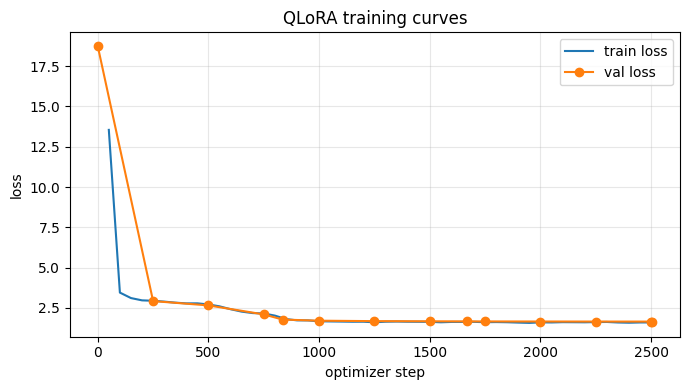

In [30]:
# 10b. Training curves (diagnostic)
import matplotlib.pyplot as plt
tr, ev = [], []
with open(log_path, encoding="utf-8") as f:
    for line in f:
        r = json.loads(line)
        if "train_loss" in r: tr.append((r["step"], r["train_loss"]))
        elif r.get("event") in ("eval", "epoch_end", "baseline"): ev.append((r.get("step", 0), r["val_loss"]))
fig, ax = plt.subplots(figsize=(7, 4))
if tr: ax.plot(*zip(*tr), label="train loss")
if ev: ax.plot(*zip(*ev), "o-", label="val loss")
ax.set_xlabel("optimizer step"); ax.set_ylabel("loss"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("QLoRA training curves"); plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=120); plt.show()


In [31]:
# 11. Restore the best adapters
best_obj = load_torch(best_path)
if best_obj["lora"] != LORA_META:
    raise RuntimeError("Best checkpoint was trained with different LoRA settings than the current configuration.")
load_qlora_state_dict(model, best_obj["adapters"])
model.to(DEVICE).eval()
print(f"Restored best adapters | step={best_obj['global_step']} | val_loss={best_obj['val_loss']:.4f}")
del best_obj

Restored best adapters | step=2505 | val_loss=1.6569


In [32]:
# Free training-time memory before generation
gc.collect()
if USE_CUDA: torch.cuda.empty_cache()

# 12. Model-2 cached decoding helpers + metrics
BLOCKED_IDS = [PAD_ID, tokenizer.unk_token_id, BOS_ID]

def build_inference_prompt(document, max_new_tokens):
    budget = min(MAX_SOURCE_TOKENS, MAX_SEQ_LEN - PREFIX_OVERHEAD - max_new_tokens)
    if budget < 256:
        raise ValueError(f"Insufficient source budget ({budget}); reduce GEN_MAX_NEW_TOKENS or MAX_TARGET_TOKENS.")
    src = select_source_ids(document)[0]
    return build_prompt_ids(src, budget)

def compute_metrics(preds, refs, use_bertscore=True):
    metrics = {}
    ensure_package("rouge_score", "rouge-score")
    from rouge_score import rouge_scorer
    scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
    scores = [scorer.score(r, p) for p, r in zip(preds, refs)]
    for k in ("rouge1", "rouge2", "rougeL"):
        metrics[f"{k}_f1"] = float(np.mean([s[k].fmeasure for s in scores]))
    if use_bertscore:
        ensure_package("bert_score", "bert-score")
        from bert_score import score as bert_score
        safe_preds = [p if p.strip() else "." for p in preds]
        _, _, f1 = bert_score(safe_preds, refs, lang="en", batch_size=BERTSCORE_BATCH_SIZE,
                              device=str(DEVICE), verbose=False)
        metrics["bertscore_f1"] = float(f1.mean().item())
    return metrics


In [33]:
# 12b. Model-2 cached decoding, tune decoding on 32 disjoint docs, then score 100 held-out docs
@torch.inference_mode()
def generate_from_prefix(prefix, max_new=GEN_MAX_NEW_TOKENS, min_new=0, ngram=0, rep=1.0):
    model.eval()
    prefix = prefix[-model.max_positions + max_new:]
    ids = torch.tensor([prefix], dtype=torch.long, device=DEVICE)
    with amp_ctx():
        h, cache = model.forward_hidden(ids, use_cache=True)
    generated = []
    seen = {}
    for step in range(min(max_new, model.max_positions - len(prefix))):
        with amp_ctx():
            logits = model.project(h[:, -1, :]).float()
        logits[:, BLOCKED_IDS] = -float("inf")
        if step < min_new:
            logits[:, EOS_ID] = -float("inf")
        if rep != 1.0 and generated:
            idx = torch.tensor([generated], dtype=torch.long, device=DEVICE)
            vals = logits.gather(1, idx)
            penalized = torch.where(vals < 0, vals * rep, vals / rep)
            logits.scatter_(1, idx, penalized)
        if ngram > 1 and len(generated) >= ngram - 1:
            key = tuple(generated[-(ngram - 1):])
            banned = seen.get(key)
            if banned:
                logits[0, list(banned)] = -float("inf")
        nxt = int(torch.argmax(logits, dim=-1).item())
        if nxt == EOS_ID:
            break
        if ngram > 1 and len(generated) >= ngram - 1:
            seen.setdefault(tuple(generated[-(ngram - 1):]), set()).add(nxt)
        generated.append(nxt)
        with amp_ctx():
            h, cache = model.forward_hidden(
                torch.tensor([[nxt]], dtype=torch.long, device=DEVICE),
                past_key_values=cache, use_cache=True
            )
    return tokenizer.decode(generated).strip()

def generate_rows(rows, gen_cfg, label):
    out, t0 = [], time.time()
    for i, row in enumerate(rows):
        prefix = build_inference_prompt(row["document"], GEN_MAX_NEW_TOKENS)
        out.append(generate_from_prefix(
            prefix, max_new=GEN_MAX_NEW_TOKENS,
            min_new=int(gen_cfg["min_frac"] * GEN_MAX_NEW_TOKENS),
            ngram=gen_cfg["ngram"], rep=gen_cfg["rep"]
        ))
        if (i + 1) % 8 == 0 or i + 1 == len(rows):
            rate = (time.time() - t0) / (i + 1)
            print(f"[{label}] {i+1}/{len(rows)} | {rate:.1f}s/doc | ETA {rate*(len(rows)-i-1)/60:.1f} min", flush=True)
    return out

# Tuning set is disjoint from final 100-document validation set.
tune_rows = val_rows[VAL_SCORE_EXAMPLES:VAL_SCORE_EXAMPLES + N_TUNE_DOCS]
val_subset = val_rows[:VAL_SCORE_EXAMPLES]
if len(tune_rows) != N_TUNE_DOCS or len(val_subset) != VAL_SCORE_EXAMPLES:
    raise ValueError("Insufficient held-out validation rows for disjoint decoding tuning and final scoring.")
assert {r["id"] for r in tune_rows}.isdisjoint(r["id"] for r in val_subset)

grid_results = []
tune_refs = [r["summary"] for r in tune_rows]
for g in GEN_GRID:
    print("\nDecoding configuration:", g)
    tune_preds = generate_rows(tune_rows, g, "decode-tune")
    m = compute_metrics(tune_preds, tune_refs, use_bertscore=True)
    row = {**g, **m, "avg_words": float(np.mean([len(x.split()) for x in tune_preds]))}
    grid_results.append(row)
    print(row)

for r_ in grid_results: r_["composite"] = composite_score(r_)  # diagnostic only
BEST_GEN = max(grid_results, key=lambda x: x["bertscore_f1"])
print("\nSelected decoding by primary BERTScore F1:", BEST_GEN)

val_preds = generate_rows(val_subset, BEST_GEN, "final-validation")
val_refs = [r["summary"] for r in val_subset]
val_metrics = compute_metrics(val_preds, val_refs, use_bertscore=True)
print("\nFINAL 100-DOC VALIDATION:", val_metrics)
print("Mean predicted words:", float(np.mean([len(x.split()) for x in val_preds])))



Decoding configuration: {'name': 'greedy', 'min_frac': 0.0, 'ngram': 0, 'rep': 1.0}
[decode-tune] 8/32 | 18.1s/doc | ETA 7.2 min
[decode-tune] 16/32 | 18.1s/doc | ETA 4.8 min
[decode-tune] 24/32 | 18.0s/doc | ETA 2.4 min
[decode-tune] 32/32 | 17.9s/doc | ETA 0.0 min


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (22 outputs left out)

{'name': 'ng8+rep1.05+min60', 'min_frac': 0.6, 'ngram': 8, 'rep': 1.05, 'rouge1_f1': 0.4395938891343776, 'rouge2_f1': 0.18879260821118587, 'rougeL_f1': 0.23085427862055957, 'bertscore_f1': 0.8293243646621704, 'avg_words': 385.5}

Selected decoding by primary BERTScore F1: {'name': 'ng8+rep1.05+min60', 'min_frac': 0.6, 'ngram': 8, 'rep': 1.05, 'rouge1_f1': 0.4395938891343776, 'rouge2_f1': 0.18879260821118587, 'rougeL_f1': 0.23085427862055957, 'bertscore_f1': 0.8293243646621704, 'avg_words': 385.5, 'composite': 0.4999241774723692}
[final-validation] 8/100 | 18.1s/doc | ETA 27.8 min
[final-validation] 16/100 | 18.1s/doc | ETA 25.3 min
[final-validation] 24/100 | 18.1s/doc | ETA 22.9 min
[final-validation] 32/100 | 18.1s/doc | ETA 20.5 min
[final-validation] 40/100 | 18.0s/doc | ETA 18.0 min
[final-validation] 48/100 | 18.0s/doc | ETA 15.6 min
[final-validation] 56/100 | 17.9s/doc | ETA 13.1 min
[final-validation] 64/100 | 17.9s/doc | ETA 10.8 min
[final-validation] 72/100 | 17.9s/doc | ET

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



FINAL 100-DOC VALIDATION: {'rouge1_f1': 0.3922001838143684, 'rouge2_f1': 0.1545265340734707, 'rougeL_f1': 0.21505129095458725, 'bertscore_f1': 0.8221357464790344}
Mean predicted words: 389.87


In [34]:
# 13. Save validation predictions, metrics and experiment metadata
with open(OUTPUT_DIR / "validation_predictions.json", "w", encoding="utf-8") as f:
    json.dump([{"id": r["id"], "summary": p, "reference": r["summary"]} for r, p in zip(val_subset, val_preds)],
              f, ensure_ascii=False, indent=2)

metadata = {
    "experiment": "Phase6-Exp3-Model2-QLoRA-NF4",
    "base_architecture": "phase1_custom_decoder_only_sinusoidal_gelu",
    "checkpoint": str(CHECKPOINT_PATH), "tokenizer": str(TOKENIZER_PATH),
    "lora": LORA_META, "trainable_parameters": trainable, "total_parameters": total,
    "max_source_tokens": MAX_SOURCE_TOKENS, "max_target_tokens": MAX_TARGET_TOKENS, "max_seq_len": MAX_SEQ_LEN,
    "micro_batch_size": MICRO_BATCH_SIZE, "grad_accum_steps": GRAD_ACCUM_STEPS, "epochs": NUM_EPOCHS,
    "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY, "warmup_ratio": WARMUP_RATIO,
    "amp_dtype": str(AMP_DTYPE) if USE_CUDA else "none",
    "gen_max_new_tokens": GEN_MAX_NEW_TOKENS, "selected_decoding": BEST_GEN, "decoding_grid": grid_results,
    "source_selector": SELECTOR_MODE, "selector_coverage": {k: float(np.mean(v)) for k, v in cov.items()},
    "train_examples": len(train_rows), "validation_examples": len(val_rows),
    "validation_scored_examples": len(val_subset),
    "validation_strategy": "duplicate-grouped split; 100 scored docs disjoint from 32 decoding-tuning docs and selector-tuning docs",
    "runtime_budget_hours": "3-4",
    "training": training_summary, "validation_metrics": val_metrics,
     "quantization": BNB_4BIT_QUANT_TYPE, "double_quantization": BNB_4BIT_USE_DOUBLE_QUANT,
    "compute_dtype": str(QLORA_COMPUTE_DTYPE),
    "seed": SEED, "torch_version": torch.__version__,
}
with open(OUTPUT_DIR / "experiment_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
print(json.dumps(metadata, indent=2))

{
  "experiment": "Phase6-Exp3-Model2-QLoRA-NF4",
  "base_architecture": "phase1_custom_decoder_only_sinusoidal_gelu",
  "checkpoint": "/kaggle/input/datasets/aaryant23/phase2-model2-ckpts/dec_full_best (8).pt",
  "tokenizer": "/kaggle/input/datasets/aaryant23/phase2-model2-ckpts/tokenizer (1).json",
  "lora": {
    "rank": 16,
    "alpha": 32,
    "dropout": 0.05,
    "quant_type": "nf4",
    "double_quant": true,
    "targets": [
      "qkv",
      "out_proj",
      "ff.0",
      "ff.2"
    ],
    "variant": "QLoRA NF4 double-quant"
  },
  "trainable_parameters": 2129920,
  "total_parameters": 49916800,
  "max_source_tokens": 1500,
  "max_target_tokens": 800,
  "max_seq_len": 2048,
  "micro_batch_size": 1,
  "grad_accum_steps": 8,
  "epochs": 3,
  "learning_rate": 0.0002,
  "weight_decay": 0.01,
  "warmup_ratio": 0.05,
  "amp_dtype": "torch.float16",
  "gen_max_new_tokens": 800,
  "selected_decoding": {
    "name": "ng8+rep1.05+min60",
    "min_frac": 0.6,
    "ngram": 8,
    "rep": 

In [35]:
# 13A. Exact Phase 6 evaluator embedded in the notebook (no separate .py file needed)
# This reproduces the supplied evaluate_phase6.py logic and runs it directly on validation outputs.
# Dependencies: rouge-score, bert-score, torch.

ensure_package("rouge_score", "rouge-score")
ensure_package("bert_score", "bert-score")
from rouge_score import tokenizers, rouge_scorer
import bert_score

def evaluator_load(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)

def evaluator_lcs(a, b):
    # Bit-parallel LCS implementation from the supplied evaluator.
    if len(a) > len(b):
        a, b = b, a
    masks = {}
    for i, token in enumerate(a):
        masks[token] = masks.get(token, 0) | (1 << i)
    state = 0
    for token in b:
        mask = masks.get(token, 0)
        x = mask | state
        y = (state << 1) | 1
        state = x & ~(x - y)
    return state.bit_count() if hasattr(int, "bit_count") else bin(state).count("1")

def evaluator_read_predictions(value):
    if isinstance(value, dict):
        output = value
    elif isinstance(value, list):
        output = {}
        for record in value:
            if not isinstance(record, dict) or "id" not in record or "summary" not in record:
                raise ValueError("Each prediction item must contain id and summary.")
            if record["id"] in output:
                raise ValueError(f"Duplicate prediction ID: {record['id']}")
            output[record["id"]] = record["summary"]
    else:
        raise ValueError("Prediction must be a JSON object or list of objects.")

    for key, summary in output.items():
        if not isinstance(key, str) or not isinstance(summary, str) or not summary.strip():
            raise ValueError(f"Invalid summary for ID {key!r}.")
    return output

def evaluate_phase6_exact(truth_file, prediction_file):
    truth = evaluator_load(truth_file)
    prediction_map = evaluator_read_predictions(evaluator_load(prediction_file))

    if not isinstance(truth, dict) or not truth:
        raise ValueError("Truth must be a non-empty JSON object.")
    if set(truth) != set(prediction_map):
        raise ValueError(
            f"ID mismatch: missing={len(set(truth)-set(prediction_map))}, "
            f"extra={len(set(prediction_map)-set(truth))}"
        )

    predictions = [prediction_map[key].strip() for key in truth]
    references = [truth[key].strip() for key in truth]

    scorer = rouge_scorer.RougeScorer(["rouge1"], use_stemmer=True)
    tokenizer = tokenizers.DefaultTokenizer(use_stemmer=True)
    rouge1 = rouge_l = 0.0

    for pred, ref in zip(predictions, references):
        scores = scorer.score(ref, pred)
        rouge1 += scores["rouge1"].fmeasure

        pred_tokens = tokenizer.tokenize(pred)
        ref_tokens = tokenizer.tokenize(ref)
        if not pred_tokens and not ref_tokens:
            rouge_l_doc = 1.0
        elif not pred_tokens or not ref_tokens:
            rouge_l_doc = 0.0
        else:
            common = evaluator_lcs(pred_tokens, ref_tokens)
            precision = common / len(pred_tokens)
            recall = common / len(ref_tokens)
            rouge_l_doc = (
                0.0 if precision + recall == 0
                else 2 * precision * recall / (precision + recall)
            )
        rouge_l += rouge_l_doc

    count = len(truth)
    rouge1 /= count
    rouge_l /= count

    device = "cuda" if torch.cuda.is_available() else "cpu"
    _, _, bert_f1 = bert_score.score(
        predictions, references, lang="en", batch_size=8,
        verbose=False, device=device
    )
    bert_f1_mean = float(bert_f1.mean().item())

    print(f"Documents: {count}")
    print(f"BERTScore F1: {bert_f1_mean:.6f}")
    print(f"ROUGE-1: {rouge1:.6f}")
    print(f"ROUGE-L: {rouge_l:.6f}")

    return {
        "documents": count,
        "bertscore_f1": bert_f1_mean,
        "rouge1": rouge1,
        "rougeL": rouge_l,
    }

# Save files in precisely the formats expected by the original evaluator.
val_truth = {str(record["id"]): record["summary"] for record in val_subset}
truth_path = OUTPUT_DIR / "validation_truth.json"
evaluator_prediction_path = OUTPUT_DIR / "validation_predictions_for_evaluator.json"

with open(truth_path, "w", encoding="utf-8") as f:
    json.dump(val_truth, f, ensure_ascii=False, indent=2)
with open(evaluator_prediction_path, "w", encoding="utf-8") as f:
    json.dump(
        [{"id": str(record["id"]), "summary": pred}
         for record, pred in zip(val_subset, val_preds)],
        f, ensure_ascii=False, indent=2
    )

print("Running embedded version of your evaluate_phase6.py")
official_validation_metrics = evaluate_phase6_exact(
    truth_path, evaluator_prediction_path
)


Running embedded version of your evaluate_phase6.py


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Documents: 100
BERTScore F1: 0.822136
ROUGE-1: 0.392200
ROUGE-L: 0.215051


In [36]:
# 14. Official test predictions -> prediction.json + submission ZIP (resumable)
FALLBACK_SUMMARY = "The judgment could not be summarized from the supplied context."

if not RUN_TEST_INFERENCE:
    print("RUN_TEST_INFERENCE=False; skipping test predictions.")
else:
    partial_path = OUTPUT_DIR / "submission_partial.jsonl"
    done = {}
    if partial_path.exists() and RESUME_TEST_PREDICTIONS:
        with open(partial_path, encoding="utf-8") as f:
            for line in f:
                if line.strip():
                    rec = json.loads(line)
                    if isinstance(rec.get("id"), str) and isinstance(rec.get("summary"), str) and rec["summary"].strip():
                        done[rec["id"]] = rec["summary"]
        print(f"Found {len(done)} cached test predictions; continuing.")

    todo = [r for r in test_records if str(r["id"]) not in done]
    t0 = time.time()
    with open(partial_path, "a" if (partial_path.exists() and RESUME_TEST_PREDICTIONS) else "w", encoding="utf-8") as f:
        for i, row in enumerate(todo, 1):
            prefix = build_inference_prompt(row["document"], GEN_MAX_NEW_TOKENS)
            summary = generate_from_prefix(
                prefix, max_new=GEN_MAX_NEW_TOKENS,
                min_new=int(BEST_GEN["min_frac"] * GEN_MAX_NEW_TOKENS),
                ngram=BEST_GEN["ngram"], rep=BEST_GEN["rep"]
            ).strip() or FALLBACK_SUMMARY
            rid = str(row["id"])
            done[rid] = summary
            f.write(json.dumps({"id": rid, "summary": summary}, ensure_ascii=False) + "\n")
            f.flush()
            if i % 5 == 0 or i == len(todo):
                rate = (time.time() - t0) / i
                print(f"[test] {len(done)}/{len(test_records)} | {rate:.1f}s/doc | ETA {rate*(len(todo)-i)/60:.1f} min", flush=True)

    test_preds = [{"id": str(r["id"]), "summary": done[str(r["id"])]} for r in test_records]
    assert len(test_preds) == len(test_records)
    assert len({x["id"] for x in test_preds}) == len(test_preds)
    assert all(x["summary"].strip() for x in test_preds)

    pred_path = OUTPUT_DIR / "prediction.json"
    with open(pred_path, "w", encoding="utf-8") as f:
        json.dump(test_preds, f, ensure_ascii=False, indent=2)

    zip_path = OUTPUT_DIR / "phase6_exp3_model2_qlora_submission.zip"
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
        zf.write(pred_path, arcname="prediction.json")

    with zipfile.ZipFile(zip_path, "r") as zf:
        names = zf.namelist()
        assert names == ["prediction.json"], f"Unexpected ZIP contents: {names}"
        archived = json.loads(zf.read("prediction.json").decode("utf-8"))
        assert len(archived) == len(test_records)
        assert [x["id"] for x in archived] == [str(r["id"]) for r in test_records]
        assert all(isinstance(x["summary"], str) and x["summary"].strip() for x in archived)

    print("JSON:", pred_path, "| records:", len(test_preds))
    print("ZIP :", zip_path, "| contents:", names)


[test] 5/100 | 17.6s/doc | ETA 27.8 min
[test] 10/100 | 17.4s/doc | ETA 26.2 min
[test] 15/100 | 17.7s/doc | ETA 25.0 min
[test] 20/100 | 17.7s/doc | ETA 23.6 min
[test] 25/100 | 17.7s/doc | ETA 22.1 min
[test] 30/100 | 17.8s/doc | ETA 20.7 min
[test] 35/100 | 17.8s/doc | ETA 19.3 min
[test] 40/100 | 17.8s/doc | ETA 17.8 min
[test] 45/100 | 17.9s/doc | ETA 16.4 min
[test] 50/100 | 17.9s/doc | ETA 14.9 min
[test] 55/100 | 17.9s/doc | ETA 13.4 min
[test] 60/100 | 17.7s/doc | ETA 11.8 min
[test] 65/100 | 17.7s/doc | ETA 10.3 min
[test] 70/100 | 17.7s/doc | ETA 8.8 min
[test] 75/100 | 17.7s/doc | ETA 7.4 min
[test] 80/100 | 17.6s/doc | ETA 5.9 min
[test] 85/100 | 17.6s/doc | ETA 4.4 min
[test] 90/100 | 17.6s/doc | ETA 2.9 min
[test] 95/100 | 17.6s/doc | ETA 1.5 min
[test] 100/100 | 17.6s/doc | ETA 0.0 min


NameError: name 'zipfile' is not defined

In [37]:
import zipfile
from pathlib import Path

zip_path = OUTPUT_DIR / "phase6_exp3_model2_qlora_submission.zip"

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(pred_path, arcname="prediction.json")

print("ZIP created:", zip_path)
print("Size (MB):", round(zip_path.stat().st_size / (1024**2), 2))

# Verify archive structure
with zipfile.ZipFile(zip_path, "r") as zf:
    print("ZIP contents:", zf.namelist())
    assert zf.namelist() == ["prediction.json"]

ZIP created: /kaggle/working/phase6_exp3_model2_qlora/phase6_exp3_model2_qlora_submission.zip
Size (MB): 0.04
ZIP contents: ['prediction.json']


In [38]:
# 14b. Sanity checks on final test predictions
lens = np.array([len(x["summary"].split()) for x in test_preds])
n_fallback = sum(x["summary"] == FALLBACK_SUMMARY for x in test_preds)
def _rep_ratio(t, n=4):
    w = t.split(); g = [tuple(w[i:i+n]) for i in range(max(0, len(w)-n+1))]
    return 1 - len(set(g)) / max(1, len(g))
rep_r = np.mean([_rep_ratio(x["summary"]) for x in test_preds])
print(f"Test predictions: {len(test_preds)} | words mean={lens.mean():.0f} median={np.median(lens):.0f} "
      f"min={lens.min()} max={lens.max()} | fallbacks={n_fallback} | repeated 4-gram ratio={rep_r:.3f}")
if n_fallback: print("WARNING: some documents received the fallback summary; inspect decoding.")


Test predictions: 100 | words mean=384 median=395 min=233 max=399 | fallbacks=0 | repeated 4-gram ratio=0.005


## Experiment 3 notes / limitations

- This is custom QLoRA: the Model-2 checkpoint is loaded in its original FP32 form, then frozen transformer linear layers are converted to bitsandbytes NF4 with double quantization.
- The tied token embedding/output matrix remains frozen in FP16; adapters are trained on fused QKV, attention output, and both FFN projections.
- The base checkpoint and tokenizer must come from the same Phase-1 Model-2 run.
- QLoRA quantization is lossy, so initial logits will not exactly match the original FP32 checkpoint. Compare baseline validation loss after quantization with the trained best checkpoint.
- If bitsandbytes reports an unsupported GPU/kernel or a quantization error, stop rather than silently falling back to ordinary LoRA.
- Keep the final 100-document validation separate from the 32-document decoding-tuning slice.


## Experiment 3 notes / limitations

- This is custom QLoRA: the Model-2 checkpoint is loaded in its original FP32 form, then frozen transformer linear layers are converted to bitsandbytes NF4 with double quantization.
- The tied token embedding/output matrix remains frozen in FP16; adapters are trained on fused QKV, attention output, and both FFN projections.
- The base checkpoint and tokenizer must come from the same Phase-1 Model-2 run.
- QLoRA quantization is lossy, so initial logits will not exactly match the original FP32 checkpoint. Compare baseline validation loss after quantization with the trained best checkpoint.
- If bitsandbytes reports an unsupported GPU/kernel or a quantization error, stop rather than silently falling back to ordinary LoRA.
- Keep the final 100-document validation separate from the 32-document decoding-tuning slice.
- Decoding is selected by BERTScore F1 because it is the primary leaderboard metric; ROUGE-1 and ROUGE-L remain reported secondary metrics.

## Run checklist

1. Upload the Phase-1 Model-2 `dec_full_best.pt` checkpoint and its matching `tokenizer.json` as Kaggle input.
2. Ensure the checkpoint is the **best** checkpoint, not `latest` from an unfinished run.
3. Run cells in order on a Kaggle T4.
4. Confirm NF4 modules are quantized, trainable parameters are adapter-only, and baseline validation loss is finite.
5. Preserve `exp3_qlora_best.pt`, `experiment_metadata.json`, validation predictions, and the submission ZIP.
